In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
training_data = pd.read_csv('../ps1/ds1_train.csv')
validation_data = pd.read_csv('../ps1/ds1_valid.csv')

features_columns = ['x_1','x_2']

In [7]:
training_data.head()

training_data.sum()

x_1     2812.660205
x_2    74198.591336
y        400.000000
dtype: float64

In [54]:

def calculate_parameter():
    y = training_data['y']
    X = training_data[features_columns]
    
    p = y.sum() / len(y)
    
    means = X.groupby(y).mean()
    mean_0 = means.loc[0].values
    mean_1 = means.loc[1].values
    
    D = X - X.groupby(y).transform('mean')
    sigma = D.T.dot(D) / len(X)

    return (p , mean_0 , mean_1, sigma)


def gaussian_density(X, mean, sigma):
    X = np.asarray(X)
    sigma = np.asarray(sigma)
    d = len(mean)

    diff = X - mean                                  
    inv = np.linalg.inv(sigma)                       
    exponent = -0.5 * np.sum((diff @ inv) * diff, axis=1)  
    norm = 1 / ((2 * np.pi) ** (d / 2) * np.sqrt(np.linalg.det(sigma)))
    return norm * np.exp(exponent)                   # 


def make_prediction(p, mean_0, mean_1, sigma, X_new):
    numerator = gaussian_density(X_new, mean_1, sigma) * p          
    other = gaussian_density(X_new, mean_0, sigma) * (1 - p)        
    denominator = numerator + other                                 

    prob_1 = np.round(numerator / denominator, 3)                             
    return prob_1


def plot(p, mean_0, mean_1, sigm):
    fig, axes = plt.subplots(figsize=(12, 8))
    class_0 = validation_data[validation_data['y'] == 0]
    class_1 = validation_data[validation_data['y'] == 1]

    axes.scatter(class_0['x_1'], class_0['x_2'], marker='o', label='y = 0')
    axes.scatter(class_1['x_1'], class_1['x_2'], marker='x', label='y = 1')

    inv = np.linalg.inv(np.asarray(sigma))

    theta = inv @ (mean_1 - mean_0)
    theta0 = 0.5 * mean_0 @ inv @ mean_0 - 0.5 * mean_1 @ inv @ mean_1 + np.log(p / (1 - p))

    x1 = np.linspace(validation_data['x_1'].min(), validation_data['x_1'].max(), 100)
    x2 = -(theta[0] * x1 + theta0) / theta[1]
    axes.plot(x1, x2, color='black', label='decision boundary')

    axes.set_ylim(validation_data['x_2'].min() - 1, validation_data['x_2'].max() + 1)

    axes.set_xlabel('x_1')
    axes.set_ylabel('x_2')
    axes.legend()
    plt.show()
    plt.savefig('../output/gda_boundary.png', dpi=300, bbox_inches='tight')

In [55]:
def main():
    p , mean_0 , mean_1, sigma = calculate_parameter()
    prob_1 = make_prediction(p , mean_0 , mean_1, sigma , validation_data[features_columns])
    prob_1 = pd.Series(prob_1)
    plot(p , mean_0 , mean_1, sigma)
    prob_1.to_csv('../output/predict_GDA')

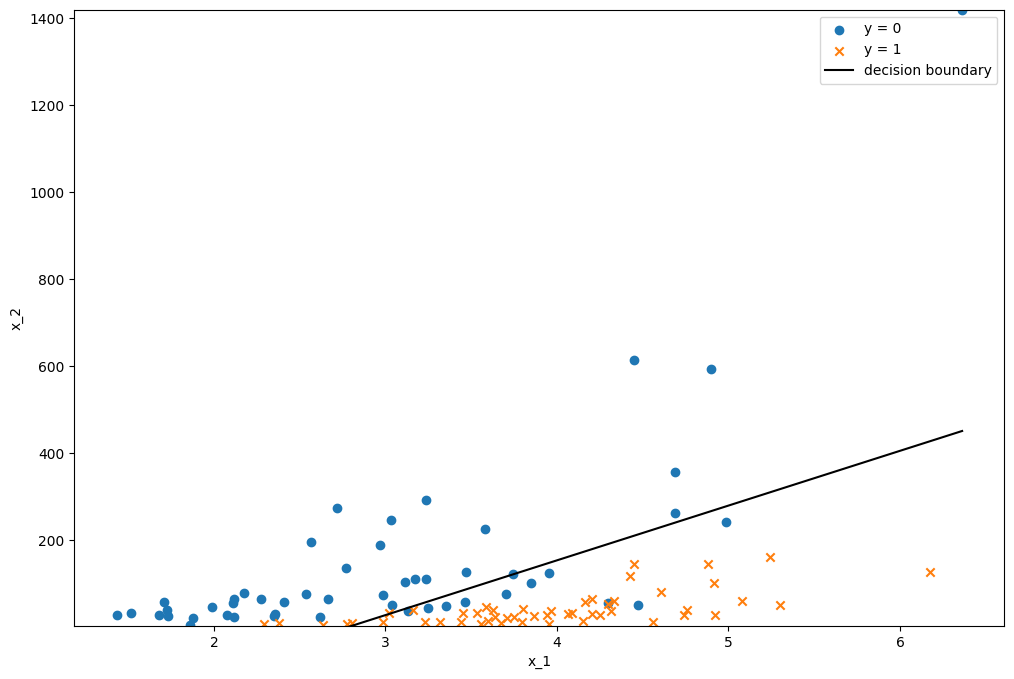

<Figure size 640x480 with 0 Axes>

In [56]:
main()